# SafeRoute crime-risk model: explore, train, evaluate, infer

The whole risk model end to end, on LAPD incidents within **5 miles of USC**:

1. **Data**: what we downloaded (`data/crime.db`)
2. **Per-crime weights**: severity × recency × time of day
3. **Features**: the training frame and whether each feature carries signal
4. **Train** XGBoost (plus sklearn's GradientBoosting for comparison)
5. **Evaluate** on 2023, which the model never saw
6. **Explain** the model with SHAP
7. **Infer** with `score_cell` / `explain_cell`, the functions the Flask API calls
8. **Sanity checks** on the saved model
9. **Model evaluation summary**

It imports the code in `algorithm/`, so a change in the scripts shows up here. Run it with
**Kernel → Restart & Run All** from the `algorithm/` folder or the repo root. It takes about
3 minutes and ~2 GB of RAM. Sections 7 and 8 use the model saved by
`python -m algorithm.models.train_xgb`; everything else trains in the notebook.

In [1]:
import sys, sqlite3, datetime as dt
from pathlib import Path

# Make `import algorithm...` work whether the kernel starts in algorithm/ or the repo root.
here = Path.cwd().resolve()
repo_root = here.parent if here.name == "algorithm" else here
sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr
import h3
from IPython.display import display

from algorithm.common import config, geo, severity
%matplotlib inline
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("repo root:", repo_root)
print("database :", config.DB_PATH)
print(f"area     : {config.RADIUS_MILES:g} miles around {config.CENTER}")

repo root: /home/user/repo
database : /home/user/repo/algorithm/data/crime.db
area     : 5 miles around (34.0224, -118.2851)


## 1. Data

If `data/crime.db` is missing, the next cell downloads it from the LA Open Data API (about a minute).

In [2]:
if not config.DB_PATH.exists():
    from algorithm.data import ingest_crime
    ingest_crime.main()

con = sqlite3.connect(config.DB_PATH)
inc = pd.read_sql("SELECT * FROM incidents", con, parse_dates=["date_occ"])
con.close()
inc["year"] = inc.date_occ.dt.year
inc["severity"] = [severity.incident_severity(c, d, w)
                   for c, d, w in zip(inc.crm_cd, inc.crm_cd_desc, inc.weapon_used_cd)]
print(f"{len(inc):,} incidents | {inc.date_occ.min():%Y-%m-%d} to {inc.date_occ.max():%Y-%m-%d} | {inc.cell.nunique():,} H3 cells")
inc[["date_occ", "hour", "crm_cd_desc", "weapon_used_cd", "severity", "tier", "cell"]].head()

396,972 incidents | 2020-01-01 to 2024-12-30 | 1,511 H3 cells


,date_occ,hour,crm_cd_desc,weapon_used_cd,severity,tier,cell
0,2020-01-08,22,BATTERY - SIMPLE ASSAULT,400,3.0,violent,8929a1d648fffff
1,2020-01-01,3,BATTERY - SIMPLE ASSAULT,500,3.0,violent,8929a1d75afffff
2,2020-01-01,5,INTIMATE PARTNER - SIMPLE ASSAULT,400,3.0,violent,8929a1d7503ffff
3,2020-03-01,21,VEHICLE - STOLEN,NaN,1.0,property,8929a1992a3ffff
4,2020-02-25,20,VEHICLE - STOLEN,NaN,1.0,property,8929a1d718fffff


### Volume over time

The drop from March 2024 is LAPD's switch to NIBRS reporting, not a real fall in crime. That is why
we train on 2020–2022, test on 2023, and use 2024 only as an extra check.

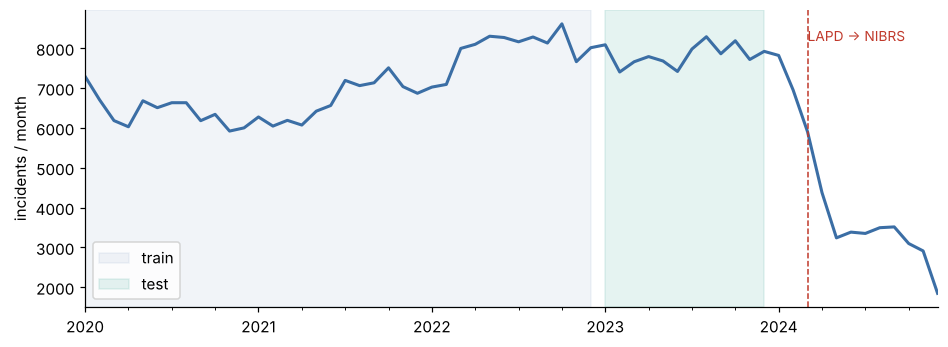

In [3]:
monthly = inc.set_index("date_occ").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, color="#3b6ea5", lw=2)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp(config.TRAIN_END), color="#3b6ea5", alpha=0.07, label="train")
ax.axvspan(pd.Timestamp(config.TEST_START), pd.Timestamp(config.TEST_END), color="#2a9d8f", alpha=0.12, label="test")
ax.axvline(pd.Timestamp("2024-03-01"), color="#c0392b", ls="--", lw=1)
ax.text(pd.Timestamp("2024-03-15"), monthly.max() * 0.95, "LAPD → NIBRS", color="#c0392b", fontsize=9)
ax.set(ylabel="incidents / month", xlabel=""); ax.legend(loc="lower left")
plt.show()

### When does it happen?

The spike at noon is partly an artifact: LAPD records `time_occ = 1200` when the time is unknown.

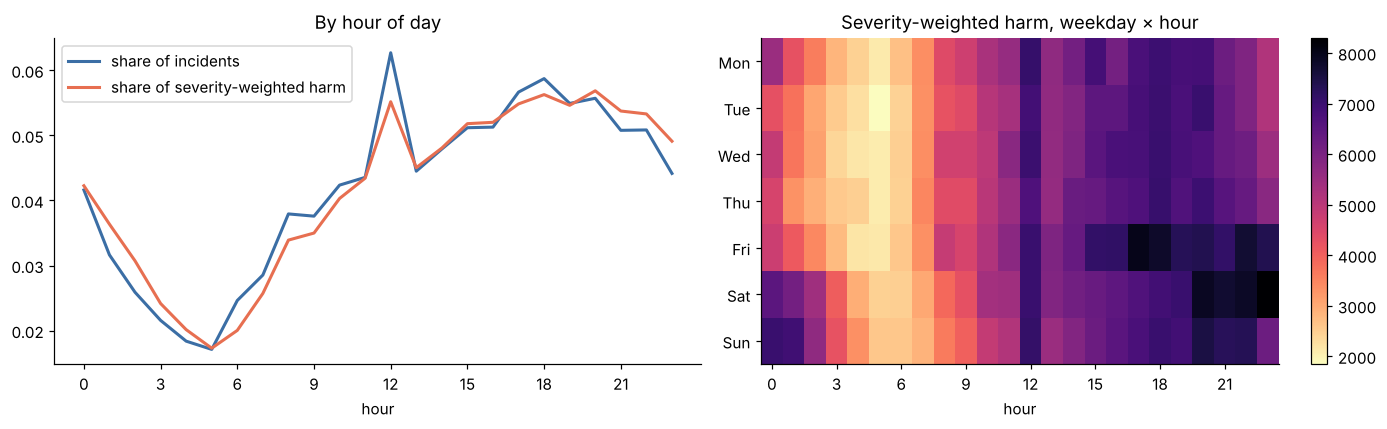

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour = inc.groupby("hour").agg(incidents=("severity", "size"), harm=("severity", "sum"))
axes[0].plot(by_hour.index, by_hour.incidents / by_hour.incidents.sum(), lw=2, color="#3b6ea5", label="share of incidents")
axes[0].plot(by_hour.index, by_hour.harm / by_hour.harm.sum(), lw=2, color="#e76f51", label="share of severity-weighted harm")
axes[0].set(xticks=range(0, 24, 3), title="By hour of day", xlabel="hour"); axes[0].legend()
grid = inc.assign(weekday=inc.date_occ.dt.day_of_week).groupby(["weekday", "hour"]).severity.sum().unstack(fill_value=0)
im = axes[1].imshow(grid, aspect="auto", cmap="magma_r")
axes[1].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set(xticks=range(0, 24, 3), xlabel="hour", title="Severity-weighted harm, weekday × hour")
plt.colorbar(im, ax=axes[1]); plt.tight_layout(); plt.show()

### Where? Incidents per H3 cell (res 9, ~370 m across)

Grey cells are inside the circle but have no LAPD records (Vernon, Huntington Park, county islands).
Blue dots are the 83 USC blue-light emergency phones.

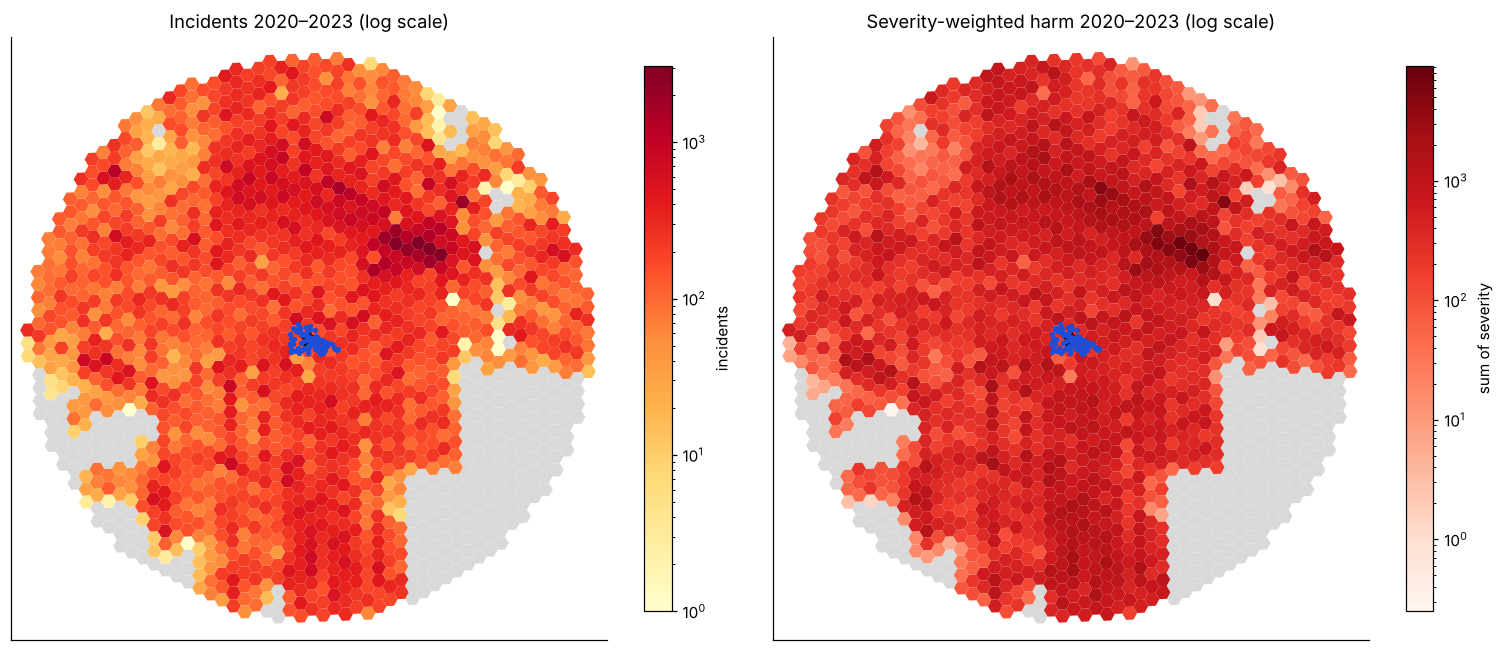

1,724 cells within 5 miles; 1,475 have LAPD incidents, 249 have none


In [5]:
def hexmap(ax, values: dict, title, cmap="YlOrRd", vmin=None, vmax=None, label="", no_data=(), norm=None):
    """Draw H3 cells coloured by value; `no_data` cells in grey."""
    if len(no_data):
        ax.add_collection(PolyCollection([[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in no_data],
                                         facecolor="#d9d9d9", edgecolor="none"))
    cells = list(values)
    polys = [[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in cells]
    pc = PolyCollection(polys, array=np.array([values[c] for c in cells], dtype=float), cmap=cmap, edgecolor="none", norm=norm)
    if vmin is not None and norm is None:
        pc.set_clim(vmin, vmax)
    ax.add_collection(pc)
    s, w, n, e = config.BBOX
    ax.set_xlim(w - 0.005, e + 0.005); ax.set_ylim(s - 0.005, n + 0.005)
    ax.set_aspect(1 / np.cos(np.radians(config.CENTER[0])))
    ax.plot(config.CENTER[1], config.CENTER[0], marker="*", color="black", ms=12)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(pc, ax=ax, shrink=0.8, label=label)

area_cells = geo.area_cells()
hist_inc = inc[inc.year <= 2023]
counts = hist_inc.groupby("cell").size()
harm = hist_inc.groupby("cell").severity.sum()
has = [c for c in area_cells if counts.get(c, 0) > 0]
empty = [c for c in area_cells if counts.get(c, 0) == 0]
phones = np.array([(a, b) for a, b, _ in geo.bluelight_phones()])
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
hexmap(axes[0], {c: counts[c] for c in has}, "Incidents 2020–2023 (log scale)", label="incidents",
       no_data=empty, norm=LogNorm(1, counts.max()))
hexmap(axes[1], {c: harm[c] for c in has}, "Severity-weighted harm 2020–2023 (log scale)", cmap="Reds",
       label="sum of severity", no_data=empty, norm=LogNorm(0.25, harm.max()))
for ax in axes:
    ax.scatter(phones[:, 1], phones[:, 0], s=6, color="#1d4ed8", zorder=5)
plt.tight_layout(); plt.show()
print(f"{len(area_cells):,} cells within {config.RADIUS_MILES:g} miles; {len(has):,} have LAPD incidents, {len(empty):,} have none")

## 2. Per-crime weights

Every past crime gets its own weight in the history features:

$$w_i = \text{severity}_i \times \frac{1}{1 + \text{age}_i / \tau} \times \exp\!\left(-\frac{\Delta h_i^2}{2\sigma^2}\right)$$

- **severity**: 0–10 harm score by LAPD crime code (`common/severity.py`). Homicide 10, rape 8,
  shootings / aggravated assault 6, robbery 5, simple assault 3, burglary 2, vehicle theft 1, fraud 0.25.
  A gun, knife or blunt weapon raises a crime by 50% (capped at 6).
- **recency**: logarithmic (power-law) decay with τ = 3 days (`config.RECENCY_*`). The weight drops by
  the same factor each time a crime's age multiplies: 1 day 0.75, 1 week 0.30, 1 month 0.09,
  1 year 0.008. A crime yesterday counts ~8× one from last month and ~90× one from last year.
- **time of day**: Gaussian on the circular hour gap, σ = 2 h (`config.TOD_SIGMA_HOURS`).

A feature is the sum of these weights over a cell's past crimes, using only crimes before the row's date.

,incidents,example,share of incidents,share of harm
severity,,,,
10.000,832,CRIMINAL HOMICIDE,0.002,0.009
8.000,2937,"RAPE, FORCIBLE",0.007,0.027
7.000,911,KIDNAPPING,0.002,0.007
6.000,51062,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",0.129,0.346
5.000,9284,ROBBERY,0.023,0.052
4.500,1354,BATTERY - SIMPLE ASSAULT,0.003,0.007
4.000,5005,BATTERY WITH SEXUAL CONTACT,0.013,0.023
3.000,70896,BATTERY - SIMPLE ASSAULT,0.179,0.240
2.000,27484,BURGLARY,0.069,0.062


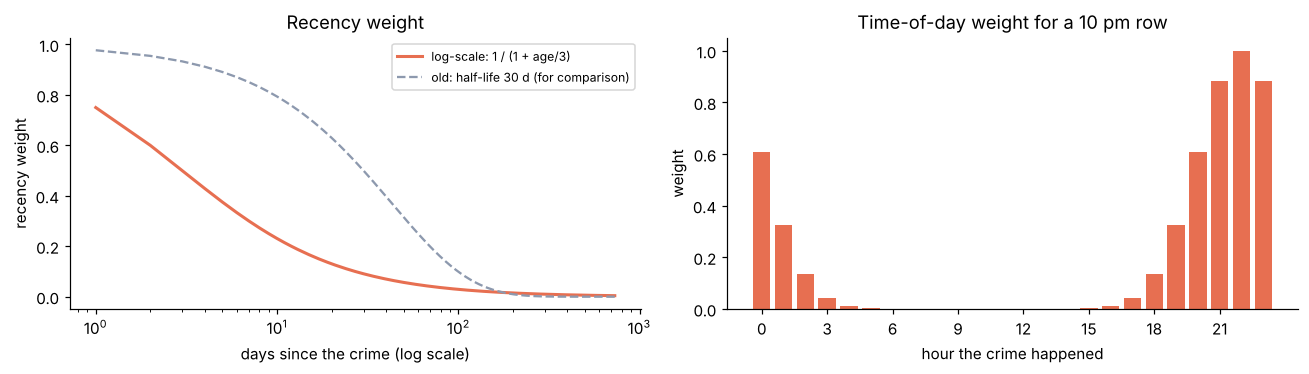

In [6]:
sev_mix = (inc.groupby("severity").agg(incidents=("crm_cd", "size"),
                                       example=("crm_cd_desc", lambda s: s.value_counts().index[0]))
           .sort_index(ascending=False))
sev_mix["share of incidents"] = (sev_mix.incidents / len(inc)).round(3)
sev_mix["share of harm"] = (sev_mix.incidents * sev_mix.index / inc.severity.sum()).round(3)
display(sev_mix)

from algorithm.features.build_dataset import tod_kernel, recency_weight
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
age = np.arange(1, 731)
axes[0].plot(age, recency_weight(age), lw=2, color="#e76f51", label=f"log-scale: 1 / (1 + age/{config.RECENCY_TAU_DAYS:g})")
axes[0].plot(age, 0.5 ** (age / 30), lw=1.5, ls="--", color="#8d99ae", label="old: half-life 30 d (for comparison)")
axes[0].set(xscale="log", xlabel="days since the crime (log scale)", ylabel="recency weight", title="Recency weight")
axes[0].legend(fontsize=8)
K = tod_kernel()
axes[1].bar(range(24), K[22], color="#e76f51")
axes[1].set(xlabel="hour the crime happened", ylabel="weight", title="Time-of-day weight for a 10 pm row", xticks=range(0, 24, 3))
plt.tight_layout(); plt.show()

### Blue-light phones

Phones can only **lower** risk. The model sees `dist_bluelight_m` with a monotone constraint (farther away
can never be safer), and scoring multiplies the probability by
`1 − 0.25 · exp(−distance / 150 m)` (`config.BLUELIGHT_*`). `geo.bluelight_protection()` gives the same
0–1 value for the route planner.

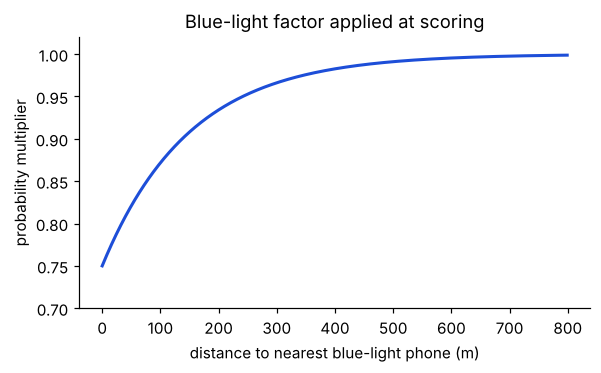

In [7]:
d = np.arange(0, 800)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(d, geo.bluelight_factor(d), lw=2, color="#1d4ed8")
ax.set(xlabel="distance to nearest blue-light phone (m)", ylabel="probability multiplier", ylim=(0.7, 1.02),
       title="Blue-light factor applied at scoring")
plt.show()

## 3. Features

Each row is one **(H3 cell, date, hour)**; the target is at least one incident in that cell during that hour.
The frame keeps every incident cell-hour plus 5 random negatives each. Column `w`
(1 for positives, 1/sample-rate for negatives) weights it back to the real grid, and the model's
outputs are prior-corrected so they are real probabilities.

In [8]:
from algorithm.features.build_dataset import History, FEATURES

hist = History()
frame, neg_rate, base_rate = hist.training_frame()
vday = hist.day_index(dt.date.fromisoformat(config.VALID_START))
tr, va = frame[frame.day < vday], frame[frame.day >= vday]
print(f"modelled cells: {len(hist.cells):,}; no-data cells: {len(hist.no_data_cells):,}")
print(f"training frame: {len(frame):,} rows, {int(frame.y.sum()):,} positives "
      f"(train {len(tr):,}, early-stopping {len(va):,})")
print(f"true base rate: {base_rate:.3%} of cell-hours have an incident; negatives kept at rate {neg_rate:.4f}")

modelled cells: 1,451; no-data cells: 273
training frame: 1,312,476 rows, 218,746 positives (train 1,066,943, early-stopping 245,533)
true base rate: 0.624% of cell-hours have an incident; negatives kept at rate 0.0314


In [9]:
FEATURE_DOCS = {
    "hour": "clock hour 0-23",
    "weekday": "day of week, 0 = Monday",
    "month": "calendar month 1-12",
    "is_weekend": "1 on Saturday/Sunday",
    "is_dark": "1 if the hour is before civil dawn or after civil dusk",
    "cell_lat": "cell centre latitude",
    "cell_lon": "cell centre longitude",
    "dist_bluelight_m": "metres to the nearest USC blue-light phone",
    "harm_recent": "Σ severity × log-scale recency, this cell",
    "harm_recent_tod": "Σ severity × log-scale recency × time-of-day weight, this cell",
    "nb1_harm_recent": "harm_recent summed over the adjacent ring of cells",
    "nb2_harm_recent": "harm_recent summed over the ring two cells out",
    "cell_hourband_365d": "incident count here at this hour ±1, previous 12 months",
    "cell_rate_all": "incidents per year here, all history",
    "cell_hourband_rate_all": "incidents per year here at this hour ±1, all history",
    "area_7d": "incidents across the whole area, previous 7 days",
}
assert set(FEATURE_DOCS) == set(FEATURES), set(FEATURES) ^ set(FEATURE_DOCS)

def wcorr(x, y, w):
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    return cov / np.sqrt(np.average((x - mx) ** 2, weights=w) * np.average((y - my) ** 2, weights=w))

pos, neg = frame[frame.y == 1], frame[frame.y == 0]
wv, yv = frame.w.to_numpy(), frame.y.to_numpy().astype(float)
summary = pd.DataFrame({
    "what it is": pd.Series(FEATURE_DOCS),
    "mean | incident": pos[FEATURES].mean(),
    "mean | no incident": neg[FEATURES].mean(),
    "corr with target": pd.Series({f: wcorr(frame[f].to_numpy(float), yv, wv) for f in FEATURES}),
}).loc[FEATURES]
summary["ratio"] = summary["mean | incident"] / summary["mean | no incident"].replace(0, np.nan)
summary.round(3)

,what it is,mean | incident,mean | no incident,corr with target,ratio
hour,clock hour 0-23,13.067000,11.498000,0.018,1.136
weekday,"day of week, 0 = Monday",3.026000,3.003000,0.001,1.008
month,calendar month 1-12,6.958000,6.927000,0.001,1.004
is_weekend,1 on Saturday/Sunday,0.286000,0.286000,0.000,1.001
is_dark,1 if the hour is before civil dawn or after ci...,0.408000,0.448000,-0.006,0.910
cell_lat,cell centre latitude,34.030998,34.028000,0.006,1.000
cell_lon,cell centre longitude,-118.282997,-118.289001,0.012,1.000
dist_bluelight_m,metres to the nearest USC blue-light phone,4190.001953,4557.815918,-0.015,0.919
harm_recent,"Σ severity × log-scale recency, this cell",12.037000,5.430000,0.077,2.217
harm_recent_tod,Σ severity × log-scale recency × time-of-day w...,2.738000,1.132000,0.077,2.420


### Correlation between features

Spearman correlation on a resample that looks like the real grid. Pairs with |ρ| ≥ 0.85 carry nearly the
same information. Trees cope with that, but SHAP splits credit between the twins, so read their
importances together.

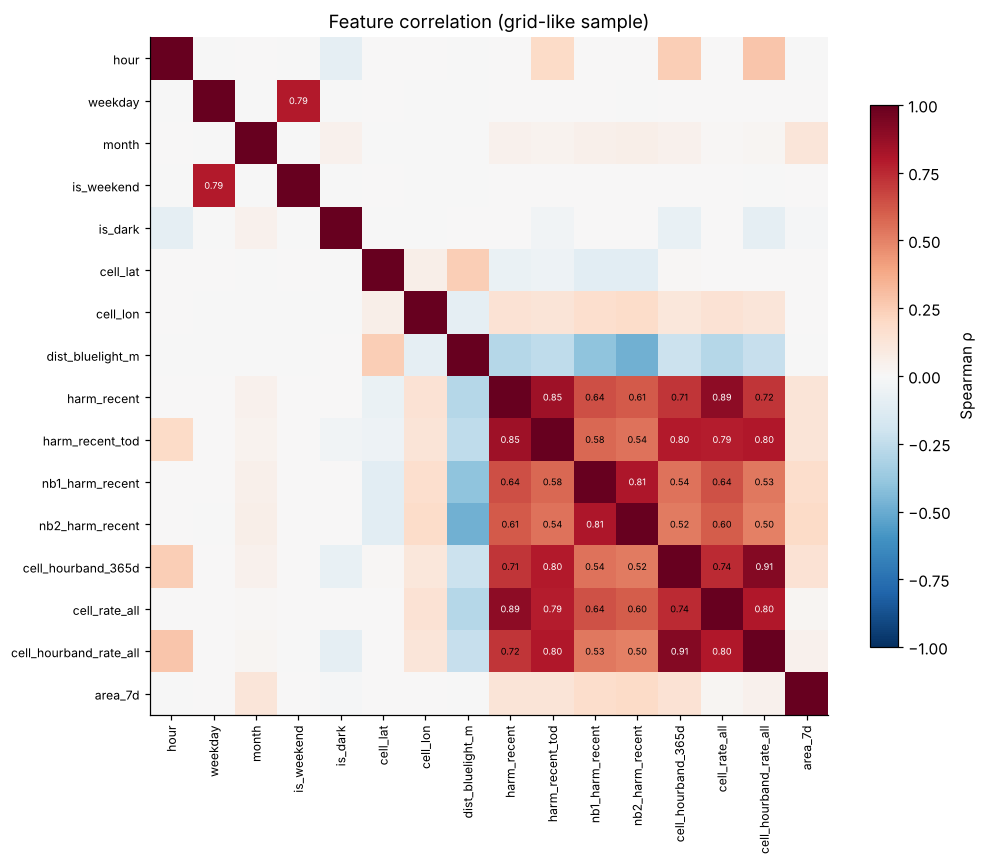

Most correlated pairs:
cell_hourband_365d  cell_hourband_rate_all    0.91
harm_recent         cell_rate_all             0.89
                    harm_recent_tod           0.85
nb1_harm_recent     nb2_harm_recent           0.81
harm_recent_tod     cell_hourband_rate_all    0.80
cell_rate_all       cell_hourband_rate_all    0.80


In [10]:
grid_like = frame.sample(n=300_000, weights="w", replace=True, random_state=1)
corr = grid_like[FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        if i != j and abs(corr.iat[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(corr.iat[i, j]) > 0.75 else "black")
plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ"); ax.set_title("Feature correlation (grid-like sample)")
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Most correlated pairs:")
print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

### Does more history mean more risk?

Rows are split into quantile bins of each history feature, and each bin's real incident rate
(Σy / Σw) is plotted. Every history feature should slope **up**.

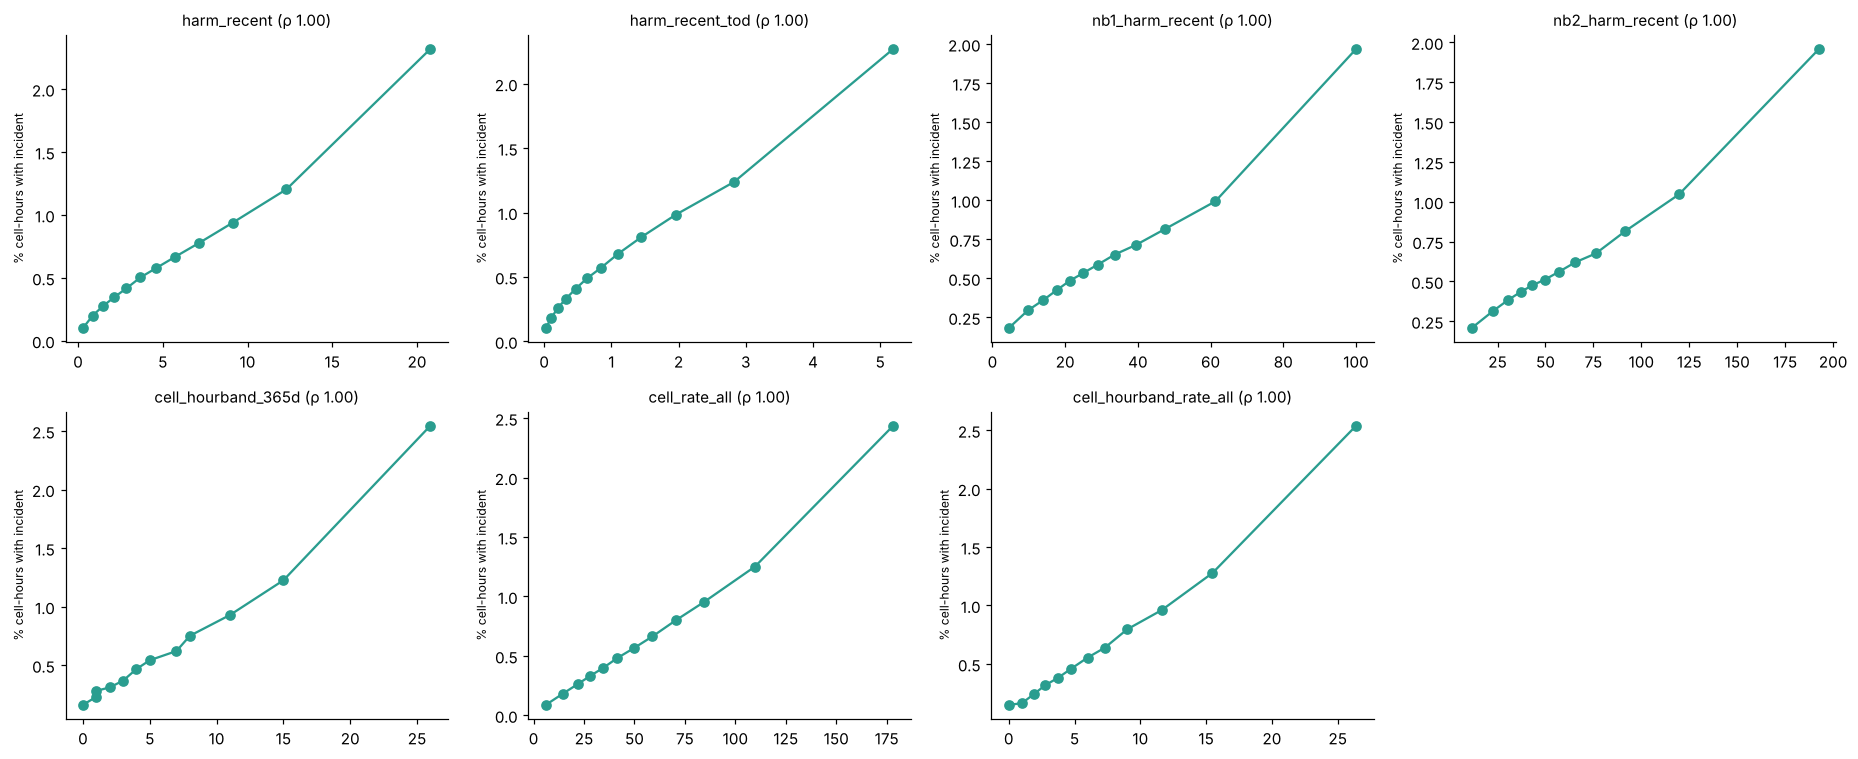

Every history feature raises the incident rate.


In [11]:
HISTORY = ["harm_recent", "harm_recent_tod", "nb1_harm_recent", "nb2_harm_recent",
           "cell_hourband_365d", "cell_rate_all", "cell_hourband_rate_all"]

def binned_rate(f, q=12):
    key = pd.qcut(frame[f].rank(method="first"), q, labels=False)
    g = pd.DataFrame({"k": key, "x": frame[f], "y": frame.y, "w": frame.w}).groupby("k")
    return pd.DataFrame({"x": g.x.median(), "rate": g.y.sum() / g.w.sum() * 100})

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
trend = {}
for ax, f in zip(axes.ravel(), HISTORY):
    b = binned_rate(f)
    trend[f] = spearmanr(b.x, b.rate).statistic
    ax.plot(b.x, b.rate, marker="o", color="#2a9d8f" if trend[f] > 0.5 else "#c0392b")
    ax.set_title(f"{f} (ρ {trend[f]:.2f})", fontsize=10); ax.set_ylabel("% cell-hours with incident", fontsize=8)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()
bad = [f for f, r in trend.items() if r <= 0.5]
print("Every history feature raises the incident rate." if not bad else f"Check these features: {bad}")

## 4. Train

Same settings as `models/train_xgb.py`. History features and `dist_bluelight_m` carry a **+1 monotone
constraint** (`config.MONOTONE_INCREASING`): more crime can only raise risk, and being farther from a
blue-light phone can never lower it.

In [12]:
import time
import xgboost as xgb
from sklearn.ensemble import GradientBoostingClassifier
from algorithm.models.train_xgb import monotone_constraints, prior_correct, evaluate, calibration_bins
%matplotlib inline

t0 = time.time()
model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist",
    eval_metric="logloss", early_stopping_rounds=150, random_state=config.SEED, n_jobs=-1,
    monotone_constraints=monotone_constraints())
model.fit(tr[FEATURES], tr.y, eval_set=[(va[FEATURES], va.y)], verbose=False)
print(f"XGBoost: best iteration {model.best_iteration} ({time.time() - t0:.0f}s)")

t0 = time.time()
sub = tr.sample(n=min(len(tr), 80_000), random_state=config.SEED)
gbc = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8,
                                 random_state=config.SEED).fit(sub[FEATURES], sub.y)
print(f"sklearn GBC: trained on {len(sub):,} rows ({time.time() - t0:.0f}s)")

XGBoost: best iteration 565 (14s)


sklearn GBC: trained on 80,000 rows (29s)


## 5. Evaluate on 2023

The full 2023 grid is ~12.7M cell-hours. The evaluation frame keeps every incident cell-hour plus a
weighted sample of the rest, so every metric below equals the full-grid number in expectation.
The baseline ranks cell-hours by last year's incident count in that cell at that hour ±1.

In [13]:
from sklearn.metrics import roc_curve, precision_recall_curve

test, _, _ = hist.eval_frame(config.TEST_START, config.TEST_END)
y, w = test.y.to_numpy(), test.w.to_numpy()
bl = geo.bluelight_factor(test.dist_bluelight_m.to_numpy())
p_xgb = prior_correct(model.predict_proba(test[FEATURES])[:, 1], neg_rate) * bl  # as served by the API
p_gbc = prior_correct(gbc.predict_proba(test[FEATURES])[:, 1], neg_rate) * bl
p_base = test.cell_hourband_365d.to_numpy() + 1e-3 * test.cell_rate_all.to_numpy()
print(f"{w.sum():,.0f} cell-hours in 2023, {int(y.sum()):,} with an incident (scored {len(test):,} rows)")
results = pd.DataFrame({
    "XGBoost": evaluate(y, p_xgb, "XGBoost", w),
    "sklearn GBC": evaluate(y, p_gbc, "sklearn GradientBoosting", w),
    "Baseline": evaluate(y, p_base, "Baseline (past-year count)", w, probabilistic=False),
}).T[["auc", "pr_auc", "top10pct_capture", "brier"]]
results.round(4)

12,710,758 cell-hours in 2023, 87,530 with an incident (scored 962,830 rows)


  XGBoost                      AUC 0.746  PR-AUC 0.0296  (base 0.0069)  top-10% capture 36.6%


  sklearn GradientBoosting     AUC 0.741  PR-AUC 0.0254  (base 0.0069)  top-10% capture 35.6%


  Baseline (past-year count)   AUC 0.734  PR-AUC 0.0291  (base 0.0069)  top-10% capture 36.0%


,auc,pr_auc,top10pct_capture,brier
XGBoost,0.7457,0.0296,0.3659,0.0068
sklearn GBC,0.7408,0.0254,0.3558,0.0068
Baseline,0.7344,0.0291,0.3599,NaN


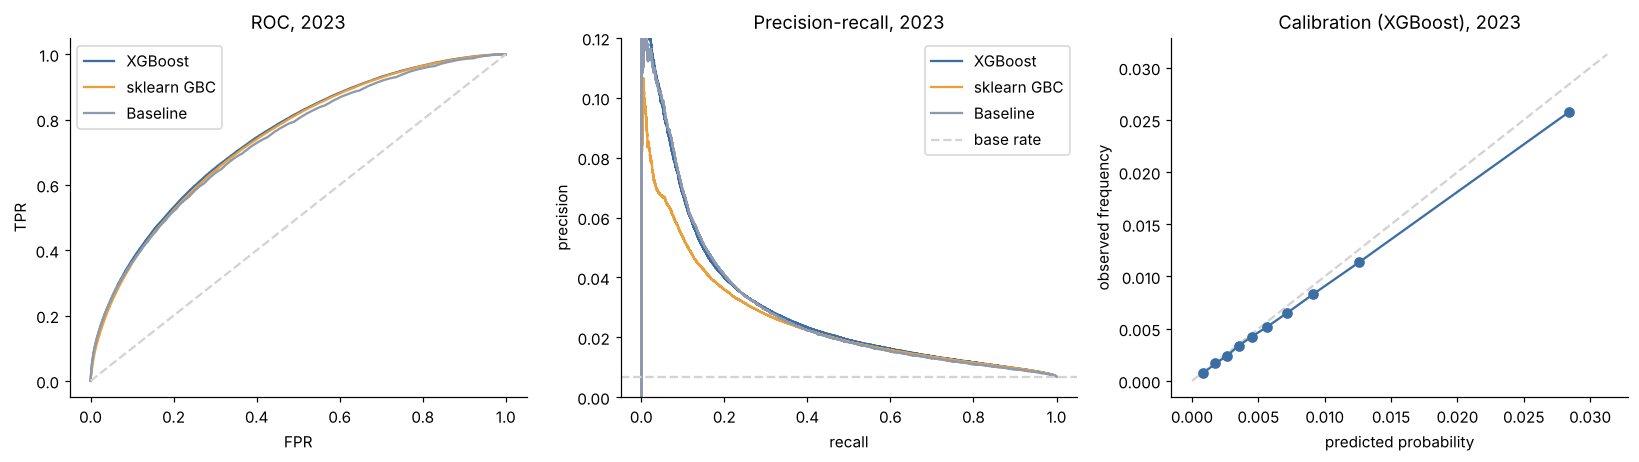

Heatmap check: predicted vs observed incidents per (cell, hour of day) over 2023, Spearman 0.72


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for name, p, c in [("XGBoost", p_xgb, "#3b6ea5"), ("sklearn GBC", p_gbc, "#e9a03b"), ("Baseline", p_base, "#8d99ae")]:
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w); axes[0].plot(fpr, tpr, label=name, color=c)
    pr, rc, _ = precision_recall_curve(y, p, sample_weight=w); axes[1].plot(rc, pr, label=name, color=c)
axes[0].plot([0, 1], [0, 1], ls="--", c="lightgray"); axes[0].set(title="ROC, 2023", xlabel="FPR", ylabel="TPR"); axes[0].legend()
axes[1].axhline(np.average(y, weights=w), ls="--", c="lightgray", label="base rate")
axes[1].set(title="Precision-recall, 2023", xlabel="recall", ylabel="precision", ylim=(0, 0.12)); axes[1].legend()
mean_pred, frac = calibration_bins(y, p_xgb, w)
hi = max(max(frac), max(mean_pred)) * 1.1
axes[2].plot([0, hi], [0, hi], ls="--", c="lightgray"); axes[2].plot(mean_pred, frac, marker="o", color="#3b6ea5")
axes[2].set(title="Calibration (XGBoost), 2023", xlabel="predicted probability", ylabel="observed frequency")
plt.tight_layout(); plt.show()

slot = (pd.DataFrame({"cell": test.cell_idx, "hour": test.hour, "pred": p_xgb * w, "obs": y})
        .groupby(["cell", "hour"]).sum())
print(f"Heatmap check: predicted vs observed incidents per (cell, hour of day) over 2023, "
      f"Spearman {slot.pred.corr(slot.obs, method='spearman'):.2f}")

## 6. Explain the model (SHAP)

Mean |SHAP| is how much each feature moves the prediction (log-odds) on a grid-like 2023 sample.
"Learned direction" is the Spearman correlation between a feature's value and its SHAP value:
positive means higher values push risk up.

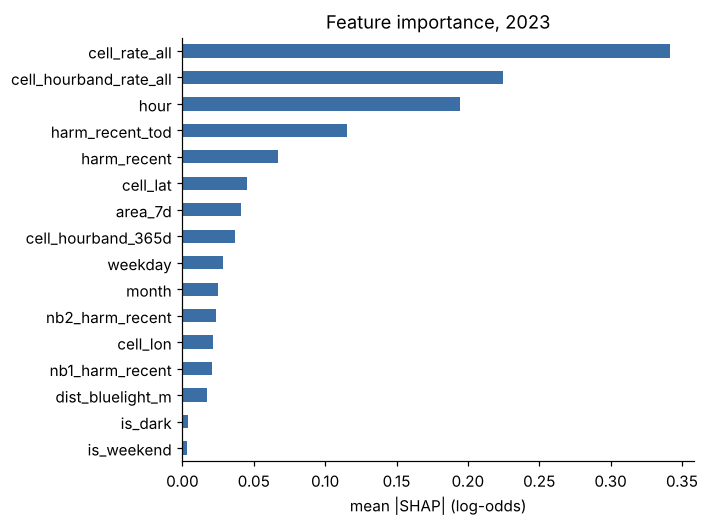

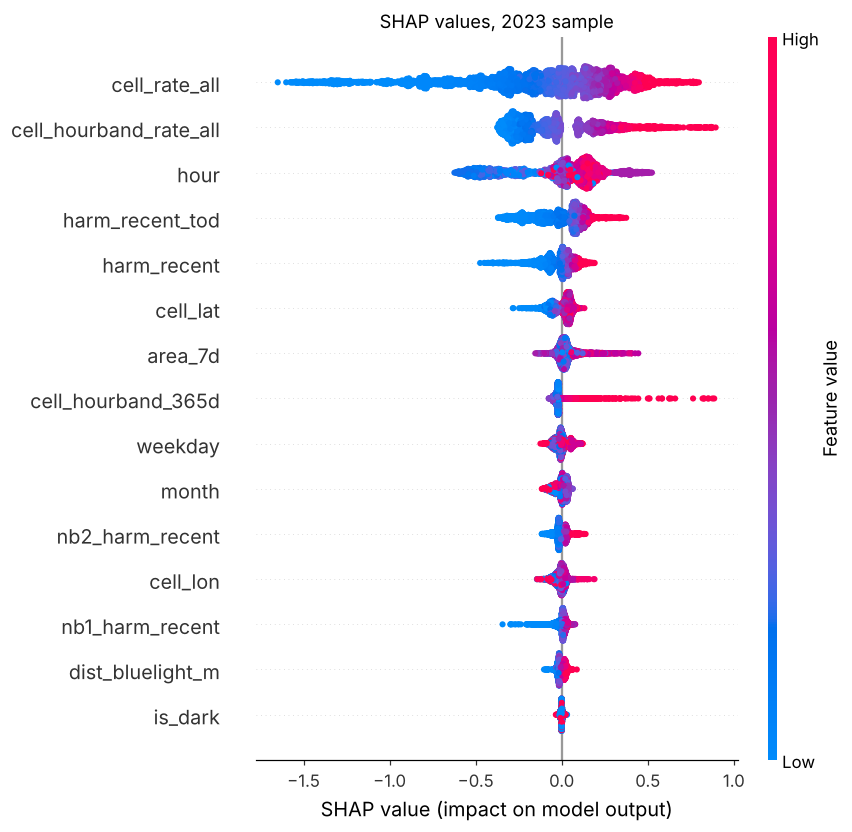

,mean |SHAP|,learned direction
cell_rate_all,0.341,0.996
cell_hourband_rate_all,0.224,0.991
hour,0.194,0.683
harm_recent_tod,0.115,0.986
harm_recent,0.067,0.987
cell_lat,0.045,0.720
area_7d,0.041,0.086
cell_hourband_365d,0.036,0.051
weekday,0.028,0.121
month,0.025,-0.260


In [15]:
sample = test.sample(5000, weights="w", random_state=config.SEED)[FEATURES]
contribs = model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)[:, :-1]
shap_table = pd.DataFrame({
    "mean |SHAP|": np.abs(contribs).mean(0),
    "learned direction": [spearmanr(sample[f], contribs[:, j]).statistic if sample[f].nunique() > 1 else np.nan
                          for j, f in enumerate(FEATURES)],
}, index=FEATURES).sort_values("mean |SHAP|", ascending=False)

fig, ax = plt.subplots(figsize=(6, 5))
shap_table["mean |SHAP|"][::-1].plot.barh(ax=ax, color="#3b6ea5")
ax.set(xlabel="mean |SHAP| (log-odds)", title="Feature importance, 2023")
plt.show()
try:  # optional: the beeswarm needs the `shap` package
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # tqdm's "IProgress not found" notice
        import shap
    shap.summary_plot(contribs, sample, max_display=15, show=False)
    plt.title("SHAP values, 2023 sample"); plt.show()
except Exception as e:
    print("SHAP beeswarm skipped:", e)
shap_table.round(3)

## 7. Inference with the saved model

`score_cell` and `explain_cell` load the model saved by `python -m algorithm.models.train_xgb`
(`models/artifacts/xgb_risk.ubj`). These are the functions the Flask API calls.

- **risk** (0–1): percentile of this cell-hour among all modelled cell-hours in 2023. Use it for colour and routing.
- **prob**: calibrated chance of at least one reported incident in that cell during that hour, after the blue-light factor.
- Cells inside the circle with no LAPD data return **None**: unknown, not safe.

In [16]:
from algorithm.scoring import score as S
from algorithm.scoring.score import score_cell, explain_cell, build_cache, cell_status

TODAY = dt.date(2026, 11, 14)
places = {
    "Tommy Trojan (USC)": (34.0206, -118.2854),
    "USC Village": (34.0254, -118.2851),
    "Figueroa & Adams": (34.0328, -118.2747),
    "DTLA, 7th St/Metro Center": (34.0486, -118.2587),
    "Koreatown, Wilshire & Western": (34.0617, -118.3089),
    "Leimert Park": (34.0049, -118.3315),
    "Hancock Park": (34.0690, -118.3360),
    "Vernon (no LAPD data)": (34.0040, -118.2300),
}
HOURS = (2, 9, 14, 18, 22)
rows = []
for name, (lat, lng) in places.items():
    cell = h3.latlng_to_cell(lat, lng, config.H3_RES)
    status = cell_status(cell)
    scores = {f"{h:02d}:00": (score_cell(cell, h, TODAY) if status == "ok" else None) for h in HOURS}
    rows.append({"place": name, "status": status, **scores})
pd.DataFrame(rows).set_index("place").round(2)

,status,02:00,09:00,14:00,18:00,22:00
place,,,,,,
Tommy Trojan (USC),ok,0.21,0.41,0.54,0.64,0.53
USC Village,ok,0.41,0.50,0.70,0.79,0.72
Figueroa & Adams,ok,0.41,0.48,0.59,0.61,0.58
"DTLA, 7th St/Metro Center",ok,0.98,0.99,0.99,0.99,0.99
"Koreatown, Wilshire & Western",ok,0.95,0.90,0.95,0.97,0.97
Leimert Park,ok,0.48,0.57,0.73,0.77,0.77
Hancock Park,ok,0.01,0.01,0.02,0.03,0.02
Vernon (no LAPD data),no_data,NaN,NaN,NaN,NaN,NaN


### Explain one score

`effect` is the SHAP contribution in log-odds: positive raises risk, negative lowers it.
`harm_score` is the per-crime weighted sum for this cell at this hour.

In [17]:
cell = h3.latlng_to_cell(*places["Figueroa & Adams"], config.H3_RES)
ex = explain_cell(cell, 22, TODAY, top_k=6)
print(f"{ex['cell']} at {ex['hour']}:00 on {ex['date']}: risk {ex['risk']:.2f}, prob {ex['prob']:.2%}, "
      f"harm_score {ex['harm_score']}, blue-light {ex['bluelight']} (history as of {ex['history_as_of']})")
pd.DataFrame(ex["factors"])[["label", "value", "effect"]]

8929a1d66abffff at 22:00 on 2026-11-14: risk 0.58, prob 0.60%, harm_score 0.345, blue-light {'dist_m': 1043, 'protection': 0.001, 'factor': 1.0} (history as of 2023-12-31)


,label,value,effect
0,time of day,22.000,0.2133
1,long-run rate here at this hour,4.250,-0.1738
2,recent serious crime here around this time of day,0.345,-0.1095
3,long-run incident rate here,37.225,-0.0823
4,"area-wide incidents, last 7 days",1639.000,0.0686
5,day of week,5.000,0.0503


### What-if: move the nearest blue-light phone

`context_features` overrides a feature for one call. Here the same USC Village cell is scored as if the
nearest phone were closer or farther away. Risk should only go down as the phone gets closer.

In [18]:
cell = h3.latlng_to_cell(*places["USC Village"], config.H3_RES)
dists = [0, 50, 100, 150, 300, 600, 1500, 5000]
bl_curve = pd.DataFrame({
    "risk at 22:00": [score_cell(cell, 22, TODAY, {"dist_bluelight_m": d}) for d in dists],
    "protection": [geo.bluelight_protection(d) for d in dists],
}, index=pd.Index(dists, name="phone distance (m)"))
bl_curve.round(3)

,risk at 22:00,protection
phone distance (m),,
0,0.678,1.000
50,0.714,0.717
100,0.738,0.513
150,0.753,0.368
300,0.775,0.135
600,0.786,0.018
1500,0.787,0.000
5000,0.789,0.000


### The heatmap the app will show

`build_cache` scores every modelled cell for all 24 hours in one call. This is what
`scoring/cache/risk_cache.json` holds.

1,451 cells × 24 hours in 3.5s; 273 no-data cells


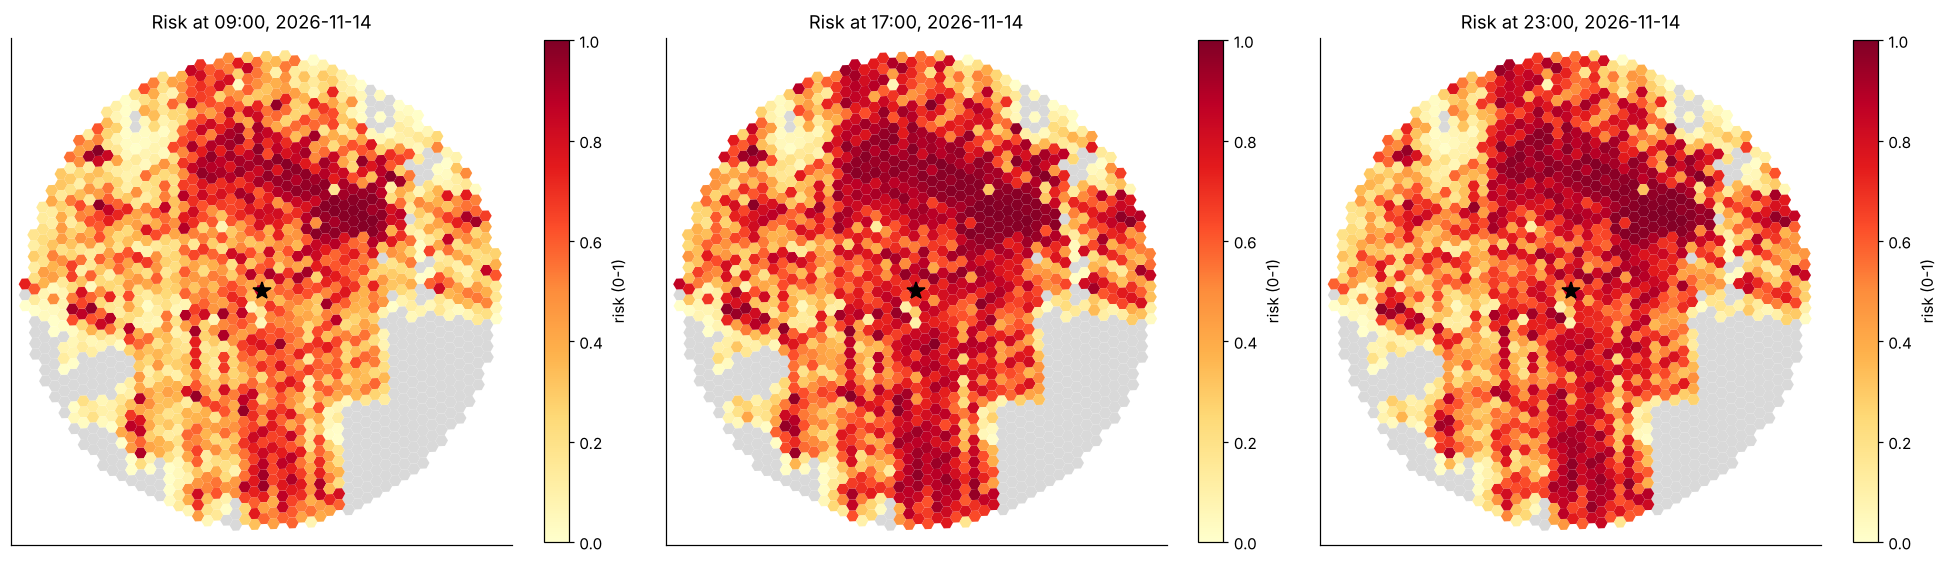

In [19]:
t0 = time.time()
cache = build_cache(TODAY)
print(f"{len(cache['cells']):,} cells × 24 hours in {time.time() - t0:.1f}s; {len(cache['no_data_cells']):,} no-data cells")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, h in zip(axes, (9, 17, 23)):
    hexmap(ax, {c: v["risk"][h] for c, v in cache["cells"].items()}, f"Risk at {h:02d}:00, {TODAY}",
           vmin=0, vmax=1, label="risk (0-1)", no_data=cache["no_data_cells"])
plt.tight_layout(); plt.show()

## 8. Sanity checks on the saved model

1. Known dangerous places score higher than quiet residential blocks, at every hour.
2. The cells with the most severity-weighted harm beat the quietest cells, at every hour.
3. Cells the model rates riskier really had more incidents in 2023.
4. **Monotone:** raising any history feature never lowers risk.
5. **Blue-light:** moving a phone closer never raises risk.
6. **Time of day:** each cell's 24-hour curve follows its own history.

Each check prints PASS or FLAG, and the summary at the end collects them.

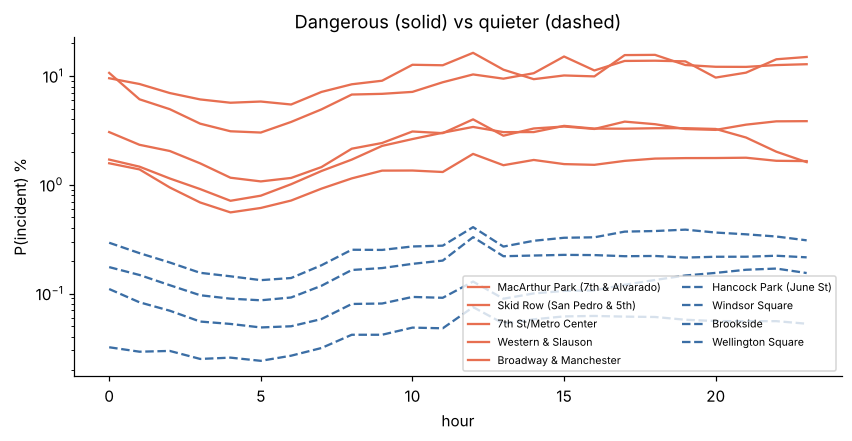

PASS in 24/24 hours; median prob ratio 32x


,00:00,03:00,06:00,09:00,12:00,15:00,18:00,21:00
MacArthur Park (7th & Alvarado),0.97,0.90,0.83,0.96,0.98,0.97,0.98,0.98
Skid Row (San Pedro & 5th),0.99,0.98,0.98,0.99,0.99,0.99,0.99,0.99
7th St/Metro Center,0.99,0.98,0.98,0.99,0.99,0.99,0.99,0.99
Western & Slauson,0.92,0.75,0.79,0.95,0.97,0.98,0.97,0.96
Broadway & Manchester,0.90,0.64,0.65,0.87,0.93,0.90,0.92,0.92
Hancock Park (June St),0.01,0.00,0.00,0.01,0.04,0.03,0.03,0.02
Windsor Square,0.07,0.02,0.02,0.04,0.09,0.07,0.10,0.14
Brookside,0.15,0.06,0.05,0.14,0.33,0.21,0.20,0.20
Wellington Square,0.28,0.12,0.10,0.24,0.41,0.32,0.38,0.35


In [20]:
CHECKS = {}
DANGEROUS = {
    "MacArthur Park (7th & Alvarado)": (34.0577, -118.2770),
    "Skid Row (San Pedro & 5th)": (34.0447, -118.2454),
    "7th St/Metro Center": (34.0486, -118.2587),
    "Western & Slauson": (33.9890, -118.3090),
    "Broadway & Manchester": (33.9601, -118.2780),
}
SAFER = {
    "Hancock Park (June St)": (34.0690, -118.3360),
    "Windsor Square": (34.0660, -118.3220),
    "Brookside": (34.0625, -118.3330),
    "Wellington Square": (34.0400, -118.3370),
}

def curves(cells):
    X = S._frame([c for c in cells for _ in range(24)], [h for _ in cells for h in range(24)], TODAY)
    prob, risk, _ = S._predict(X)
    return prob.reshape(len(cells), 24), risk.reshape(len(cells), 24)

def to_cells(places):
    return [h3.latlng_to_cell(a, b, config.H3_RES) for a, b in places.values()]

dp, dr = curves(to_cells(DANGEROUS)); sp, sr = curves(to_cells(SAFER))
fig, ax = plt.subplots(figsize=(9, 4))
for i, n in enumerate(DANGEROUS): ax.plot(dp[i] * 100, color="#e76f51", label=n)
for i, n in enumerate(SAFER): ax.plot(sp[i] * 100, color="#3b6ea5", ls="--", label=n)
ax.set(yscale="log", xlabel="hour", ylabel="P(incident) %", title="Dangerous (solid) vs quieter (dashed)")
ax.legend(fontsize=7, ncol=2); plt.show()
ok = dp.min(0) > sp.max(0)
CHECKS["1. dangerous places > quiet places, every hour"] = bool(ok.all())
print("PASS" if ok.all() else "FLAG", f"in {ok.sum()}/24 hours; median prob ratio {np.median(dp.mean(0) / sp.mean(0)):.0f}x")
pd.DataFrame(np.vstack([dr, sr])[:, ::3], index=list(DANGEROUS) + list(SAFER),
             columns=[f"{h:02d}:00" for h in range(0, 24, 3)]).round(2)

In [21]:
train_inc = inc[(inc.date_occ <= config.TRAIN_END) & inc.cell.isin(set(hist.cells))]
cell_harm = train_inc.groupby("cell").severity.sum().reindex(hist.cells, fill_value=0).sort_values()
top_cells, low_cells = list(cell_harm.index[-10:]), list(cell_harm.index[:10])
tp, trisk = curves(top_cells); lp, lrisk = curves(low_cells)
ok = tp.min(0) > lp.max(0)
CHECKS["2. most-harm cells > quietest cells, every hour"] = bool(ok.all())
print("PASS" if ok.all() else "FLAG", f"in {ok.sum()}/24 hours; mean risk {trisk.mean():.2f} vs {lrisk.mean():.2f}")

per_cell = pd.DataFrame({"cell": test.cell_idx, "pred": p_xgb * w, "obs": y}).groupby("cell").sum()
rho_cell = spearmanr(per_cell.pred, per_cell.obs).statistic
dec = per_cell.groupby(pd.qcut(per_cell.pred.rank(method="first"), 10, labels=False)).obs.sum()
CHECKS["3. predicted vs actual per cell trends up"] = bool(rho_cell > 0.7 and dec.is_monotonic_increasing)
print("PASS" if CHECKS["3. predicted vs actual per cell trends up"] else "FLAG",
      f"per-cell Spearman {rho_cell:.2f}; 2023 incidents per predicted-risk decile: {dec.astype(int).tolist()}")

PASS in 24/24 hours; mean risk 0.99 vs 0.01
PASS per-cell Spearman 0.96; 2023 incidents per predicted-risk decile: [1055, 2383, 3595, 4786, 5757, 7060, 8648, 10413, 13848, 29985]


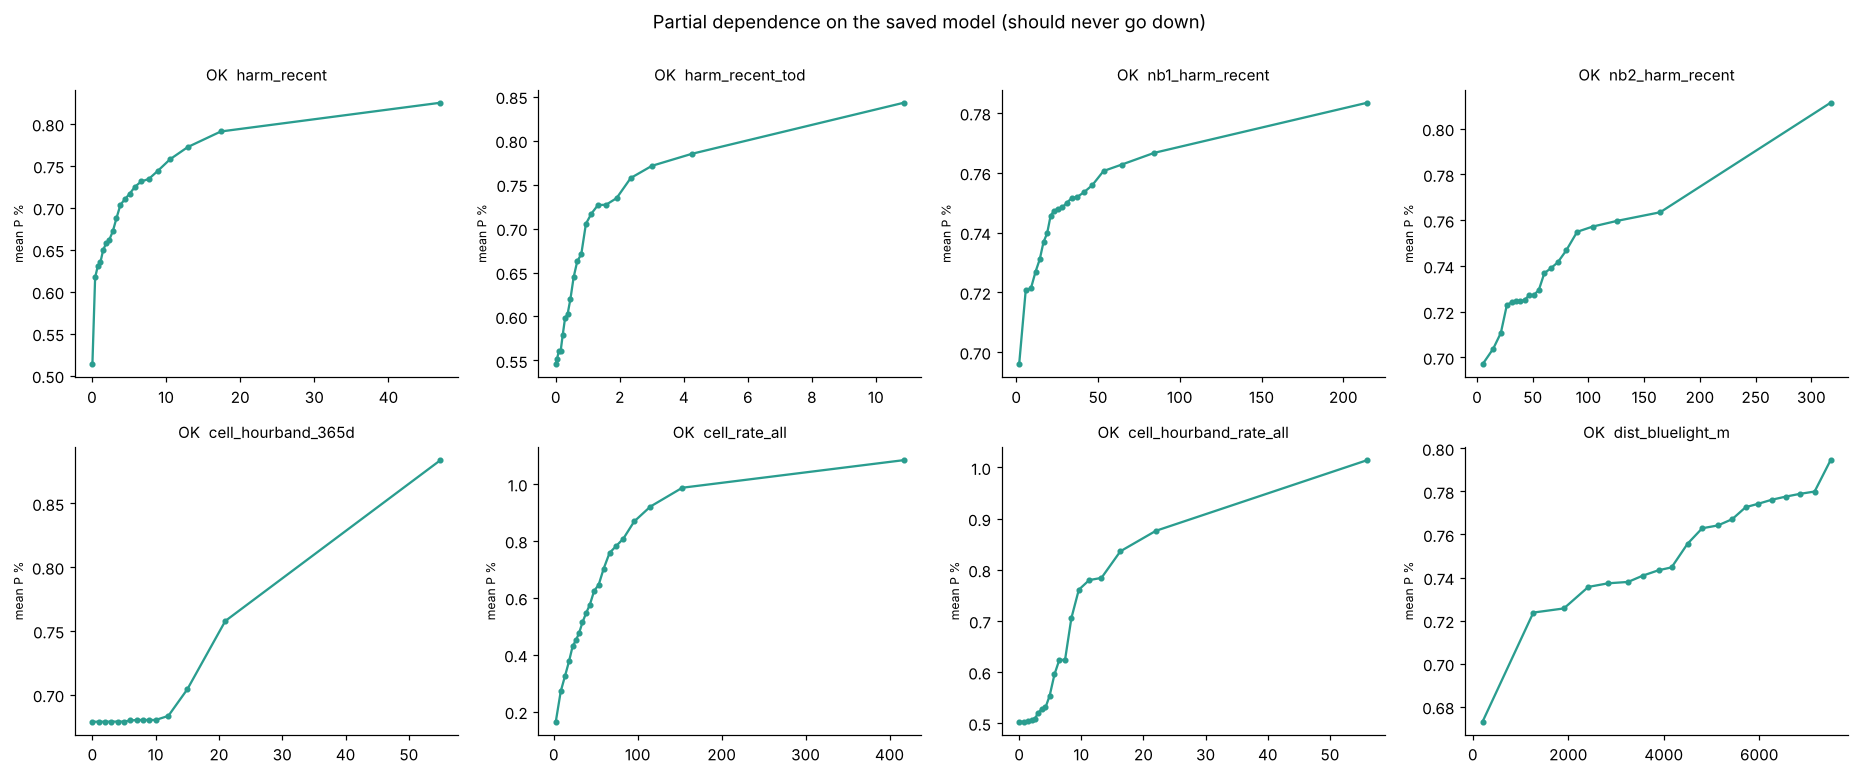

{'harm_recent': 'OK', 'harm_recent_tod': 'OK', 'nb1_harm_recent': 'OK', 'nb2_harm_recent': 'OK', 'cell_hourband_365d': 'OK', 'cell_rate_all': 'OK', 'cell_hourband_rate_all': 'OK', 'dist_bluelight_m': 'OK'}


In [22]:
pd_rows = test.sample(3000, weights="w", random_state=3)[FEATURES].reset_index(drop=True)
CONSTRAINED = config.MONOTONE_INCREASING
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
mono = {}
for ax, f in zip(axes.ravel(), CONSTRAINED):
    grid = np.unique(np.quantile(frame[f], np.linspace(0.01, 0.99, 20)))
    curve = np.array([S._predict(pd_rows.assign(**{f: v}))[0].mean() for v in grid])
    mono[f] = bool((np.diff(curve) >= -1e-12).all())
    ax.plot(grid, curve * 100, marker=".", color="#2a9d8f" if mono[f] else "#c0392b")
    ax.set_title(("OK  " if mono[f] else "FLAG  ") + f, fontsize=10); ax.set_ylabel("mean P %", fontsize=8)
plt.suptitle("Partial dependence on the saved model (should never go down)", y=1.0)
plt.tight_layout(); plt.show()
CHECKS["4. monotone in every history feature"] = all(v for f, v in mono.items() if f != "dist_bluelight_m")
CHECKS["5. blue-light phone closer never raises risk"] = bool(mono["dist_bluelight_m"] and bl_curve["risk at 22:00"].is_monotonic_increasing)
print({f: "OK" if v else "FLAG" for f, v in mono.items()})

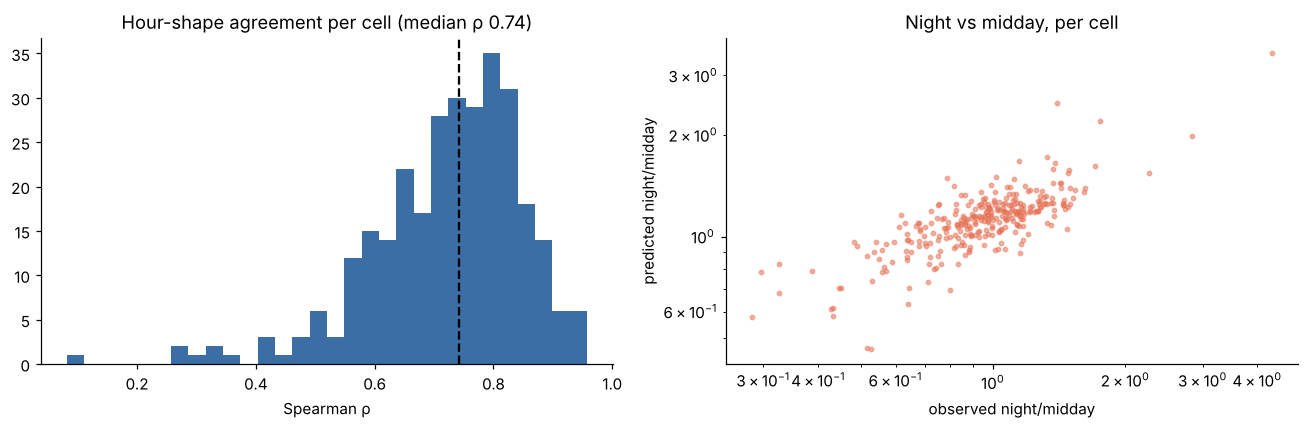

PASS median ρ 0.74; 100% of 58 night-heavy cells predicted night-heavy


In [23]:
busy = list(train_inc.groupby("cell").size().sort_values().index[-300:])
obs_prof = (train_inc[train_inc.cell.isin(busy)].groupby(["cell", "hour"]).size()
            .unstack(fill_value=0).reindex(index=busy, columns=range(24), fill_value=0))
pp, _ = curves(busy)
rho_cells = np.array([spearmanr(pp[i], obs_prof.iloc[i]).statistic for i in range(len(busy))])
night, midday = [20, 21, 22, 23, 0, 1], [10, 11, 12, 13, 14]
obs_ratio = obs_prof[night].mean(axis=1) / obs_prof[midday].mean(axis=1).clip(lower=1e-9)
pred_ratio = pp[:, night].mean(axis=1) / pp[:, midday].mean(axis=1)
night_heavy = (obs_ratio > 1.2).to_numpy()
agree = (pred_ratio[night_heavy] > 1).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rho_cells, bins=30, color="#3b6ea5"); axes[0].axvline(np.median(rho_cells), color="black", ls="--")
axes[0].set(title=f"Hour-shape agreement per cell (median ρ {np.median(rho_cells):.2f})", xlabel="Spearman ρ")
axes[1].scatter(obs_ratio, pred_ratio, s=8, alpha=0.5, color="#e76f51")
axes[1].set(xscale="log", yscale="log", xlabel="observed night/midday", ylabel="predicted night/midday", title="Night vs midday, per cell")
plt.tight_layout(); plt.show()
CHECKS["6. time of day follows each cell's history"] = bool(np.median(rho_cells) > 0.6 and agree > 0.9)
print("PASS" if CHECKS["6. time of day follows each cell's history"] else "FLAG",
      f"median ρ {np.median(rho_cells):.2f}; {agree:.0%} of {night_heavy.sum()} night-heavy cells predicted night-heavy")

In [24]:
print("All checks pass." if all(CHECKS.values()) else "Some checks flagged; see the cells above.")
pd.Series({k: "PASS" if v else "FLAG" for k, v in CHECKS.items()}, name="result").to_frame()

All checks pass.


,result
"1. dangerous places > quiet places, every hour",PASS
"2. most-harm cells > quietest cells, every hour",PASS
3. predicted vs actual per cell trends up,PASS
4. monotone in every history feature,PASS
5. blue-light phone closer never raises risk,PASS
6. time of day follows each cell's history,PASS


## 9. Model evaluation (summary)

The final numbers on the 2023 test year, which the model never saw in training. Uses the weighted
predictions from section 5, so every number is a full-grid estimate.

- **ROC-AUC**: how well the model ranks risky cell-hours above safe ones (0.5 = random).
- **PR-AUC** and **lift**: precision-recall area, and how many times better that is than the base rate.
- **Top-10% capture**: share of all incidents in the 10% of cell-hours the model ranks riskiest.
- **Brier / log loss**: how close the probabilities are to what happened (lower is better). The baseline is a count, so it has none.
- **Calibration**: predicted vs observed incident rate in 10 equal-sized bins of the model's predictions.

In [25]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss

def top_capture(y, p, w, frac=0.10):
    order = np.argsort(-p)
    in_top = np.cumsum(w[order]) <= frac * w.sum()
    return (y[order] * in_top).sum() / y.sum()

base = np.average(y, weights=w)
final = pd.DataFrame({
    name: {
        "ROC-AUC": roc_auc_score(y, p, sample_weight=w),
        "PR-AUC": average_precision_score(y, p, sample_weight=w),
        "PR-AUC lift": average_precision_score(y, p, sample_weight=w) / base,
        "Top-10% capture": top_capture(y, p, w),
        "Brier": brier_score_loss(y, p, sample_weight=w) if is_prob else np.nan,
        "Log loss": log_loss(y, p, sample_weight=w) if is_prob else np.nan,
    }
    for name, p, is_prob in [("XGBoost", p_xgb, True), ("sklearn GBC", p_gbc, True), ("Baseline", p_base, False)]
}).T
display(final.round(4))

order = np.argsort(p_xgb)
decile = np.empty(len(p_xgb), dtype=int)
decile[order] = np.minimum((np.cumsum(w[order]) / w.sum() * 10).astype(int), 9) + 1
cal = pd.DataFrame({"d": decile, "p": p_xgb * w, "y": y, "w": w}).groupby("d").sum()
cal = pd.DataFrame({"predicted %": cal.p / cal.w * 100, "observed %": cal.y / cal.w * 100}).rename_axis("decile")
display(cal.round(3))

x = final.loc["XGBoost"]
print(f"2023 base rate: {base:.2%} of cell-hours have an incident.")
print(f"XGBoost ROC-AUC {x['ROC-AUC']:.3f} vs baseline {final.loc['Baseline', 'ROC-AUC']:.3f}; PR-AUC is {x['PR-AUC lift']:.1f}x the base rate.")
print(f"The riskiest 10% of cell-hours hold {x['Top-10% capture']:.0%} of all incidents.")
print(f"Calibration: predicted and observed rates differ by at most {(cal['predicted %'] - cal['observed %']).abs().max():.3f} points per decile.")

,ROC-AUC,PR-AUC,PR-AUC lift,Top-10% capture,Brier,Log loss
XGBoost,0.7457,0.0296,4.3032,0.3660,0.0068,0.0380
sklearn GBC,0.7408,0.0254,3.6817,0.3559,0.0068,0.0383
Baseline,0.7344,0.0291,4.2320,0.3600,NaN,NaN


,predicted %,observed %
decile,,
1,0.085,0.074
2,0.177,0.167
3,0.262,0.239
4,0.352,0.336
5,0.449,0.424
6,0.567,0.519
7,0.713,0.648
8,0.914,0.831
9,1.257,1.135


2023 base rate: 0.69% of cell-hours have an incident.
XGBoost ROC-AUC 0.746 vs baseline 0.734; PR-AUC is 4.3x the base rate.
The riskiest 10% of cell-hours hold 37% of all incidents.
Calibration: predicted and observed rates differ by at most 0.265 points per decile.


## Caveats

- LAPD data shows what gets **reported and policed**, not where harm actually happens. Show the factors
  behind each score (`explain_cell`) and use risk as a cost on routes, not a hard block.
- Severity scores and half-lives are design choices (documented in `common/severity.py` and
  `common/config.py`), not learned. Change them there and retrain.
- The blue-light reduction (up to 25%) is a policy choice: phones sit where people already walk, so the
  data alone can't show their deterrent effect.
- For dates after 2023, history features are anchored at the end of 2023, the last full year before
  the NIBRS reporting drop.
- Grey cells (inside 5 miles, no LAPD data) are other police jurisdictions, mostly Vernon, Huntington
  Park and county islands.